# Steam game recommendations: implicit-feedback ALS against a course method and baselines

**Our outside-the-course method** is matrix factorisation for implicit feedback (Hu, Koren & Volinsky, 2008), fitted with alternating least squares (ALS). Every user and game gets a vector of latent factors, and their dot product scores how likely the user is to play the game. A played game is a positive with confidence $c = 1 + \alpha$, an unplayed game a weak negative with confidence 1. Like the other methods, ALS uses only which games each user played (playtime only decides whether a game counts as played). ALS alternately solves for all user vectors with the game vectors fixed and the other way round; each half-step is a set of small least-squares problems, implemented from scratch in `recommender/als.py` (NumPy + Numba).

**Course topics.** Two course topics are essential parts of the pipeline. *Frequent itemsets* give the course recommender ALS is compared with: association rules from PCY (pairs) and Apriori (triples), written by us (`recommender/itemsets.py`, `recommender/rules.py`); Apriori's pruning is what makes the triples feasible (on all baskets at support 100: 39.4 million candidate triples instead of the 3.1 billion triples of the 2,657 frequent games, `frequent_itemsets.ipynb`). *Clustering* (spherical k-means; k compared with the Davies–Bouldin index and seed agreement) describes the learned game vectors and is what the diversification of the lists is built on.

**Baselines.** Two further recommenders complete the comparison: item-item similarity (item-kNN, with the cosine or the Jaccard similarity of the games' player sets, computed exactly because 3,718 games make all pairs cheap) and popularity.

**Data:** the Australian Steam user inventories, reviews and game metadata from Julian McAuley's group at UCSD (https://cseweb.ucsd.edu/~jmcauley/datasets.html; Kang & McAuley, ICDM 2018; Wan & McAuley, RecSys 2018; Pathak, Gupta & McAuley, SIGIR 2017).

Outline:
1. Data: played games, one shared filter, train / validation / test split.
2. Tuning: every method is tuned on validation with the same rule.
3. Convergence of ALS.
4. Test results over five random splits, with bootstrap intervals, and running times.
5. Cross-check of our ALS against the `implicit` library.
6. What ALS learned: similar games, and clusters of game vectors compared with Steam tags.
7. Diversifying the lists by cluster.

**How to run.** From the repository root: `pip install -r requirements-recommender.txt`, then run all cells. The slow parts (tuning grids, test runs over five splits, convergence traces) are cached as CSV files in `results/`, so a re-run takes about 15 minutes; delete a file there to recompute that part (all of them: several hours on a 12-core laptop). The unit tests run with `pytest`.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from recommender import als, baselines, clusters, data, diversify, evaluate, itemsets
from recommender import experiments as ex

FIGURES = Path(data.DATA_DIR).parent / "figures"
FIGURES.mkdir(exist_ok=True)
N_SEEDS = 5                    # random splits for the test results
CONVERGENCE_SEEDS = 3
CONVERGENCE_SWEEPS = 30
CLUSTER_KS = [10, 20, 40]      # numbers of clusters for diversification
CAPS = [1, 2, 3, 4, 5, 10]     # at most this many games per cluster in a top-10 list (10 = no cap)
CHECK_FACTORS = 128            # size of the cross-check against implicit (any size tests the code)
STABLE_ARI = 0.9               # clusters are described at the largest k this reproducible across seeds

# Figures are sized for the report (two columns, 178 mm wide; one column in the appendix) with no text below 10 pt.
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]      # categorical colours, always in this order
SIZES = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # one blue from light to dark, for ordered sizes
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.prop_cycle": plt.cycler(color=SERIES),
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
                     "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
                     "lines.linewidth": 2})

## 1. Data

All methods share one data definition (`recommender/data.py`). The raw inventories repeat some users; duplicate (user, game) rows keep the largest playtime. A game counts for a user only if it was **played**: owned-but-unplayed games are left out, because bundles and giveaways make ownership weak evidence of taste, and every method is trained and scored on plays. Games need at least 50 players and users at least 5 played games; removing games can push users below 5 and the other way round, so the two filters repeat until both hold. Players are counted over all played games, including the ones set aside below for validation and testing, so a game can end up with fewer than 50 training players (the minimum is printed below).

In [2]:
raw = data.read_user_items()
user_items = data.deduplicate(raw)
print(f"{len(raw):,} raw user-game rows, {len(raw) - len(user_items):,} duplicates removed, "
      f"{(user_items['playtime'] > 0).sum():,} played")

inter = data.build_interactions(user_items)
n_users, n_games = inter.playtime.shape
display(inter.filter_log)
print(f"{n_users:,} users x {n_games:,} games: {inter.playtime.nnz / (n_users * n_games):.2%} of the matrix is played")

5,153,209 raw user-game rows, 59,127 duplicates removed, 3,246,352 played


,users,games,played pairs
step,,,
played entries,68403,10050,3246352
filter pass 1,59717,3720,3146315
filter pass 2,59716,3718,3146213
filter pass 3,59716,3718,3146213


59,716 users x 3,718 games: 1.42% of the matrix is played


For every user, 20% of their played games go to the **test** set; of the rest, another 20% go to the **validation** set used for all tuning. The filter runs before the split, so it defines the population we evaluate: active users and games with at least 50 players. Recommending niche games is therefore not measured.

In [3]:
train_full, test = data.split_per_user(inter.playtime, test_frac=0.2, seed=0)
train, valid = data.split_per_user(train_full, test_frac=0.2, seed=1)
print(f"train {train.nnz:,}  validation {valid.nnz:,}  test {test.nnz:,} played pairs")

players = data.players_per_game(train)
print("training players per game: min {}, quartiles {}".format(players.min(), np.percentile(players, [25, 50, 75])))

train 2,013,843  validation 503,425  test 628,945 played pairs
training players per game: min 20, quartiles [ 58.   128.5  397.75]


## 2. Tuning every method with the same rule

Each method gets a grid of settings, scored on the validation games by NDCG@10. The same rule picks the setting for every method:

- **One-standard-error rule:** take the simplest setting whose NDCG is within one standard error (over users) of the best. "Simpler" is fixed in the code: pairs-only rules before rules with triples and higher supports before lower ones; fewer neighbours for item-kNN; for ALS fewer factors, then smaller α (less weight on the played games), then larger λ. λ is only compared at the same α, because the confidences, and with them the strength of a given λ, grow with α.
- **Edge check:** the best value of every ordered setting should lie inside the range tried, so that more tuning would be unlikely to change the comparison. Allowed edges are natural bounds (pairs only; one or all neighbours) and the stated compute cap of 512 factors. For ALS, a best λ or α at the edge makes the grid grow one step further out until it is inside, and so does a one-SE pick at the edge of the λ or α values tried, so that the rule has seen the setting past its pick (see below).

A well-tuned simple baseline is the real test for a learned model (Ferrari Dacrema et al., 2019), so the rules and baselines get wide grids. They are the textbook forms (no shrinkage or other refinements), so a more elaborate kNN could narrow the gap.

### Association rules (frequent itemsets)

Rules come from the frequent itemsets of the training baskets: pairs with support ≥ `pair_support` (PCY), and optionally triples with support ≥ `triple_support` (Apriori), which add rules with two-game premises {a, b} → c. A user's score for a game is the strongest rule into it (`max`) or the sum of all of them (`sum`). Supports are counts of users in the tuning split. Rules are ranked by confidence, as in the course; interest (lift) would correct for popular consequents but was not tried.

In [4]:
triple_cache = {}  # triples depend only on their support, so mine each support once
rules_grid = ex.run_grid("tune_rules", ex.rule_configs(), lambda c: ex.score(
    ex.rules_scorer(train, c["pair_support"], c["triple_support"], c["aggregate"], triple_cache), train, valid))
rules_grid["uses triples"] = rules_grid["triple_support"] > 0
rule_simplicity = [("uses triples", True), ("pair_support", False), ("triple_support", False)]

rules_pairs, _ = ex.one_se_choice(rules_grid[~rules_grid["uses triples"]], rule_simplicity)
rules_triples, _ = ex.one_se_choice(rules_grid[rules_grid["uses triples"]], rule_simplicity)
rules_choice, rules_best = ex.one_se_choice(rules_grid, rule_simplicity)

display(rules_grid.sort_values("ndcg@10", ascending=False).head(8).round(4))
rule_keys = ["pair_support", "triple_support", "aggregate"]
display(pd.concat([
    ex.edge_check(rules_grid, row, rule_keys, ["pair_support", "triple_support"], {"triple_support": [0]}).assign(setting_of=name)
    for name, row in [("best", rules_best), ("chosen, pairs only", rules_pairs), ("chosen, with triples", rules_triples)]
], ignore_index=True))
print(f"chosen pairs-only {rules_pairs['ndcg@10']:.4f}, chosen with triples {rules_triples['ndcg@10']:.4f} "
      f"(SE {rules_pairs['ndcg_se']:.4f})")

,pair_support,triple_support,aggregate,precision@10,recall@10,ndcg@10,ndcg_se,coverage,uses triples
8,60,0,max,0.1382,0.2371,0.2399,0.0009,0.1022,False
16,120,0,max,0.1378,0.2367,0.2395,0.0009,0.0689,False
12,60,150,max,0.1393,0.2395,0.2394,0.0009,0.0858,True
4,30,150,max,0.1394,0.2397,0.2394,0.0009,0.1240,True
14,60,300,max,0.1383,0.2378,0.2387,0.0009,0.0871,True
20,120,150,max,0.1384,0.2387,0.2385,0.0009,0.0600,True
0,30,0,max,0.1374,0.2362,0.2385,0.0009,0.1503,False
6,30,300,max,0.1382,0.2378,0.2383,0.0009,0.1315,True


,setting,best,tried,at edge,allowed edge,setting_of
0,pair_support,60,"[30, 60, 120, 250]",False,False,best
1,triple_support,0,"[0, 60, 150, 300]",True,True,best
2,pair_support,120,"[30, 60, 120, 250]",False,False,"chosen, pairs only"
3,triple_support,0,"[0, 60, 150, 300]",True,True,"chosen, pairs only"
4,pair_support,120,"[30, 60, 120, 250]",False,False,"chosen, with triples"
5,triple_support,150,"[0, 60, 150, 300]",False,False,"chosen, with triples"


chosen pairs-only 0.2395, chosen with triples 0.2385 (SE 0.0009)


### Item-item similarity (item-kNN)

A user's score for a game is the summed similarity between it and the games they played, keeping each game's `k` most similar games. Similarity is cosine or Jaccard (the similar-items measure from the course) of the two games' player sets; `k` = number of games means all neighbours.

In [5]:
knn_grid = ex.run_grid("tune_knn", ex.knn_configs(n_games), lambda c: ex.score(
    ex.knn_scorer(train, c["measure"], c["k"]), train, valid))
knn_choice, knn_best = ex.one_se_choice(knn_grid, [("k", True)])

display(knn_grid.sort_values("ndcg@10", ascending=False).head(8).round(4))
display(ex.edge_check(knn_grid, knn_best, ["measure", "k"], ["k"], {"k": [1, n_games]}))

,measure,k,precision@10,recall@10,ndcg@10,ndcg_se,coverage
16,cosine,5,0.1359,0.2379,0.2295,0.0009,0.5551
15,cosine,2,0.1316,0.2287,0.2279,0.0009,0.6307
19,jaccard,5,0.1330,0.2292,0.2211,0.0009,0.5382
18,jaccard,2,0.1276,0.2194,0.2200,0.0009,0.6450
0,cosine,10,0.1298,0.2282,0.2194,0.0009,0.3195
6,cosine,3718,0.1231,0.2179,0.2173,0.0009,0.2039
5,cosine,500,0.1227,0.2170,0.2166,0.0009,0.1982
4,cosine,200,0.1215,0.2143,0.2145,0.0009,0.1942


,setting,best,tried,at edge,allowed edge
0,k,5,"[1, 2, 5, 10, 20, 50, 100, 200, 500, 3718]",False,False


### ALS

Four stages, because a full grid over three settings is too slow:
1. Factors {64, 128, 256} × λ from 30 to 3000 (α = 10), plus λ ∈ {1, 10} at 128 factors to show what happens without strong regularisation.
2. 512 factors (the compute cap) at the λ values around the best 256-factor λ.
3. α ∈ {3, 10, 30} around the best (factors, λ).
4. Edge extensions, repeated until nothing is added: for every α whose best λ, and for the one-SE pick, is the smallest or largest λ tried, the next λ further out (`ex.reg_extensions`); if the best α (each α at its own best λ), or the one-SE pick's α, is the smallest or largest α tried, the next α in {0.3, 1, 3, 10, 30, 100, 300} at the λ values around that setting's λ (`ex.alpha_extensions`), after which its λ is tuned the same way.

Every fit runs 15 sweeps; the last column is the relative change of the loss in the last sweep, so convergence can be checked for every setting, not only the one traced in Section 3. The least converged fits are printed below. Factors were only varied in stages 1–2 (α = 10); the λ table shows how much 512 factors add over 256.

In [6]:
def als_eval(cfg):
    model, change = ex.als_with_convergence(train, cfg)
    return {**ex.score(evaluate.als_scorer(model), train, valid), "last_sweep_loss_change": change}

als_keys = ex.ALS_KEYS
stage1 = ex.run_grid("tune_als", ex.als_stage1_configs(), als_eval)
cap = ex.run_grid("tune_als", ex.als_cap_configs(stage1), als_eval)
stage2 = ex.run_grid("tune_als", ex.als_stage2_configs(pd.concat([stage1, cap])), als_eval)
als_grid = pd.concat([stage1, cap, stage2]).drop_duplicates(als_keys, ignore_index=True)
als_simplicity = [("factors", True), ("alpha", True), ("reg", False)]
als_pick = lambda grid: ex.one_se_choice(grid, als_simplicity)

before_extensions = len(als_grid)
while extension := (ex.reg_extensions(als_grid, chosen=[als_pick(als_grid)[0]])
                    + ex.alpha_extensions(als_grid, chosen=[als_pick(als_grid)[0]])):
    als_grid = pd.concat([als_grid, ex.run_grid("tune_als", extension, als_eval)]).drop_duplicates(
        als_keys, ignore_index=True)
print(f"edge extensions added {len(als_grid) - before_extensions} settings")

als_choice, als_best = als_pick(als_grid)
chosen_als = {k: als_choice[k] for k in als_keys}

display(als_grid.sort_values("ndcg@10", ascending=False).head(10).round(4))
display(pd.concat([
    ex.edge_check(als_grid, row, als_keys, ["factors", "alpha", "reg"], {"factors": [ex.ALS_MAX_FACTORS]},
                  free={"alpha": ["reg"]}).assign(setting_of=name)
    for name, row in [("best", als_best), ("chosen", als_choice)]
], ignore_index=True))
print("validation NDCG at 512 factors, per α and λ:")
display(als_grid[als_grid["factors"] == ex.ALS_MAX_FACTORS].pivot_table(
    index="alpha", columns="reg", values="ndcg@10").round(4))
print(f"chosen NDCG {als_choice['ndcg@10']:.4f}, best {als_best['ndcg@10']:.4f} (SE {als_best['ndcg_se']:.4f}); "
      f"the chosen setting is {als_choice['ndcg@10'] - (als_best['ndcg@10'] - als_best['ndcg_se']):.5f} above the one-SE threshold")
print(f"{len(als_grid)} settings; least converged fits:")
display(als_grid.nlargest(3, "last_sweep_loss_change")[als_keys + ["ndcg@10", "last_sweep_loss_change"]])

edge extensions added 9 settings


,alpha,factors,reg,precision@10,recall@10,ndcg@10,ndcg_se,coverage,last_sweep_loss_change
46,30.0,512,375.0,0.1542,0.2651,0.2590,0.0009,0.3147,0.0001
44,30.0,512,300.0,0.1540,0.2645,0.2581,0.0009,0.3860,0.0002
35,10.0,512,250.0,0.1535,0.2610,0.2572,0.0009,0.1891,0.0000
25,10.0,256,250.0,0.1530,0.2603,0.2564,0.0009,0.1864,0.0000
51,30.0,512,450.0,0.1521,0.2622,0.2562,0.0009,0.2614,0.0000
38,10.0,512,200.0,0.1540,0.2604,0.2559,0.0009,0.2595,0.0000
36,10.0,512,300.0,0.1503,0.2565,0.2530,0.0009,0.1485,0.0000
26,10.0,256,300.0,0.1500,0.2561,0.2526,0.0009,0.1469,0.0000
52,100.0,512,450.0,0.1484,0.2617,0.2520,0.0009,0.4860,0.0008
43,30.0,512,250.0,0.1506,0.2586,0.2519,0.0009,0.4349,0.0003


,setting,best,tried,at edge,allowed edge,setting_of
0,factors,512.0,[512],True,True,best
1,alpha,30.0,"[3.0, 10.0, 30.0, 100.0]",False,False,best
2,reg,375.0,"[200.0, 250.0, 300.0, 375.0, 450.0]",False,False,best
3,factors,512.0,[512],True,True,chosen
4,alpha,30.0,"[3.0, 10.0, 30.0, 100.0]",False,False,chosen
5,reg,375.0,"[200.0, 250.0, 300.0, 375.0, 450.0]",False,False,chosen


validation NDCG at 512 factors, per α and λ:


reg,30.0,100.0,200.0,250.0,300.0,375.0,450.0,700.0
alpha,,,,,,,,
3.0,0.1187,0.2434,0.2388,0.2248,0.2123,NaN,NaN,NaN
10.0,NaN,NaN,0.2559,0.2572,0.2530,0.2415,NaN,NaN
30.0,NaN,NaN,0.2389,0.2519,0.2581,0.2590,0.2562,NaN
100.0,NaN,NaN,NaN,0.2268,0.2389,0.2480,0.2520,0.2468


chosen NDCG 0.2590, best 0.2590 (SE 0.0009); the chosen setting is 0.00091 above the one-SE threshold
54 settings; least converged fits:


,alpha,factors,reg,ndcg@10,last_sweep_loss_change
33,10.0,128,1.0,0.151471,0.003666
0,10.0,64,30.0,0.184112,0.001328
11,10.0,128,30.0,0.160148,0.001265


Validation NDCG against λ for each number of factors (α = 10): too little regularisation lets the larger models overfit, too much holds every size back.

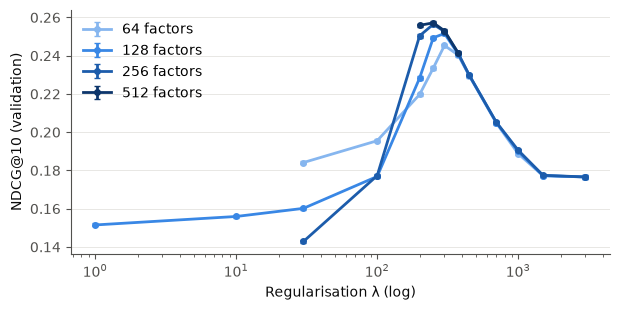

reg,1.0,10.0,30.0,100.0,200.0,250.0,300.0,375.0,450.0,700.0,1000.0,1500.0,3000.0
factors,,,,,,,,,,,,,
64,NaN,NaN,0.1841,0.1955,0.2197,0.2335,0.2453,0.2404,0.2295,0.2047,0.1887,0.1772,0.1766
128,0.1515,0.1559,0.1601,0.1768,0.2283,0.2494,0.2516,0.2410,0.2297,0.2050,0.1900,0.1773,0.1766
256,NaN,NaN,0.1428,0.1773,0.2504,0.2564,0.2526,0.2413,0.2298,0.2052,0.1905,0.1774,0.1766
512,NaN,NaN,NaN,NaN,0.2559,0.2572,0.2530,0.2415,NaN,NaN,NaN,NaN,NaN


In [7]:
curve = als_grid[als_grid["alpha"] == ex.ALS_ALPHA]
fig, ax = plt.subplots(figsize=(6.3, 3.2))
for colour, (factors, part) in zip(SIZES, curve.groupby("factors")):
    part = part.sort_values("reg")
    ax.errorbar(part["reg"], part["ndcg@10"], yerr=part["ndcg_se"], color=colour, marker="o", ms=4, capsize=2,
                label=f"{factors} factors")
ax.set_xscale("log")
ax.set_xlabel("Regularisation λ (log)")
ax.set_ylabel("NDCG@10 (validation)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "als_lambda.pdf")
plt.show()
display(curve.pivot_table(index="factors", columns="reg", values="ndcg@10").round(4))

### Chosen settings

The table lists, per method, how many settings were tried, the setting the one-SE rule picked, and its validation NDCG next to the best one.

In [8]:
def describe(row, keys):
    return ", ".join(f"{k}={row[k]:g}" if isinstance(row[k], (int, float, np.integer, np.floating)) else f"{k}={row[k]}" for k in keys)

rule_keys = ["pair_support", "triple_support", "aggregate"]
summary = pd.DataFrame([
    ("Association rules (pairs)", (~rules_grid["uses triples"]).sum(), describe(rules_pairs, rule_keys), rules_pairs["ndcg@10"], rules_grid.loc[~rules_grid["uses triples"], "ndcg@10"].max()),
    ("Association rules (pairs + triples)", rules_grid["uses triples"].sum(), describe(rules_triples, rule_keys), rules_triples["ndcg@10"], rules_grid.loc[rules_grid["uses triples"], "ndcg@10"].max()),
    ("Item-kNN", len(knn_grid), describe(knn_choice, ["measure", "k"]), knn_choice["ndcg@10"], knn_grid["ndcg@10"].max()),
    ("ALS", len(als_grid), describe(als_choice, als_keys), als_choice["ndcg@10"], als_grid["ndcg@10"].max()),
], columns=["method", "settings tried", "chosen setting", "chosen NDCG@10", "best NDCG@10"])
display(summary.round(4))

,method,settings tried,chosen setting,chosen NDCG@10,best NDCG@10
0,Association rules (pairs),8,"pair_support=120, triple_support=0, aggregate=max",0.2395,0.2399
1,Association rules (pairs + triples),24,"pair_support=120, triple_support=150, aggregat...",0.2385,0.2394
2,Item-kNN,20,"measure=cosine, k=5",0.2295,0.2295
3,ALS,54,"alpha=30, factors=512, reg=375",0.2590,0.2590


## 3. Convergence of ALS

Training loss and validation NDCG after every sweep for the chosen ALS setting, from three random starting points, run to 30 sweeps. The loss is computed sparsely (`als.loss`), without forming the full users × games matrix.

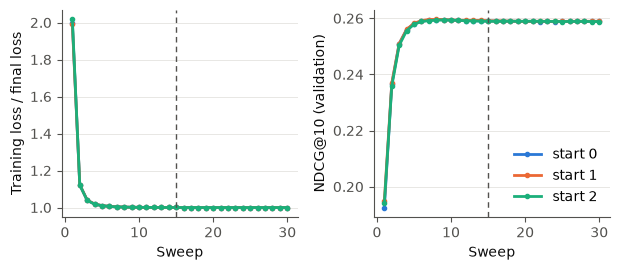

NDCG at sweep 15: [0.259, 0.2591, 0.2589]; at sweep 30: [0.2589, 0.2589, 0.2589]
loss within 1% of its final value from sweep 6 for every start; mean NDCG peaks at sweep 8 (0.2595)


In [9]:
slug = "_".join(f"{k}{chosen_als[k]:g}" for k in als_keys)
trace = ex.cached_table(f"convergence_{slug}_sweeps{CONVERGENCE_SWEEPS}_starts{CONVERGENCE_SEEDS}", lambda: pd.concat(
    [ex.convergence_trace(train, valid, chosen_als, seed, CONVERGENCE_SWEEPS) for seed in range(CONVERGENCE_SEEDS)]))

fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.8))
for seed, part in trace.groupby("seed"):
    axes[0].plot(part["sweep"], part["loss"] / part["loss"].iloc[-1], marker=".", label=f"start {seed}")
    axes[1].plot(part["sweep"], part["ndcg@10"], marker=".", label=f"start {seed}")
axes[0].set_ylabel("Training loss / final loss")
axes[1].set_ylabel("NDCG@10 (validation)")
for ax in axes:
    ax.axvline(ex.ITERATIONS, color=MUTED, ls=(0, (4, 3)), lw=1)
    ax.set_xlabel("Sweep")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "als_convergence.pdf")
plt.show()

at = trace.pivot(index="sweep", columns="seed", values="ndcg@10")
print(f"NDCG at sweep {ex.ITERATIONS}: {at.loc[ex.ITERATIONS].round(4).tolist()}; at sweep {CONVERGENCE_SWEEPS}: {at.loc[CONVERGENCE_SWEEPS].round(4).tolist()}")
loss_ratio = trace.groupby("seed")["loss"].transform(lambda s: s / s.iloc[-1])
peak = at.mean(axis=1)
print(f"loss within 1% of its final value from sweep {trace[loss_ratio < 1.01].groupby('seed')['sweep'].min().max()} for every start; "
      f"mean NDCG peaks at sweep {peak.idxmax()} ({peak.max():.4f})")

## 4. Test results

Each method is refitted on training + validation games with its chosen setting and scored on the test games. Refitting brings back the validation games, so each basket holds about 1.25× as many games; a support threshold for k-item sets is scaled by that factor to the power k so it keeps its meaning (`itemsets.scale_support`). The other settings are kept: there is no simple rule like the support scaling for ALS's λ, and item-kNN's k counts neighbours, not users.

The whole comparison is repeated on five random splits (seed 0 is the split used for tuning; the settings stay fixed). The other four splits put different games in the test set, so some of their test games were training or validation games during tuning: they show how much the result moves with the split, but they are not fresh held-out data. Besides accuracy we report:
- **coverage**: share of all games recommended to at least one user;
- **long-tail share**: share of recommended slots filled with games outside the 20% of games with the most players;
- **intra-list similarity**: mean cosine similarity of the games' player sets (co-play similarity) between the games in a list; lower means more varied lists.

In [10]:
def scaled(cfg):
    return {
        "pair_support": itemsets.scale_support(int(cfg["pair_support"]), train, train_full, 2),
        "triple_support": itemsets.scale_support(int(cfg["triple_support"]), train, train_full, 3),
        "aggregate": str(cfg["aggregate"]),
    }

as_als = lambda row: {"alpha": float(row["alpha"]), "factors": int(row["factors"]), "reg": float(row["reg"])}
settings = {
    "rules_pairs": scaled(rules_pairs),
    "rules_triples": scaled(rules_triples),
    "knn": {"measure": str(knn_choice["measure"]), "k": int(knn_choice["k"])},
    "als": as_als(als_choice),
}
print(f"games per basket grow {train_full.nnz / train.nnz:.3f}x on refit; settings: {settings}")

test_scores, diversity, per_user = ex.test_runs(inter.playtime, list(range(N_SEEDS)), settings, CLUSTER_KS, CAPS)

games per basket grow 1.250x on refit; settings: {'rules_pairs': {'pair_support': 187, 'triple_support': 0, 'aggregate': 'max'}, 'rules_triples': {'pair_support': 187, 'triple_support': 293, 'aggregate': 'max'}, 'knn': {'measure': 'cosine', 'k': 5}, 'als': {'alpha': 30.0, 'factors': 512, 'reg': 375.0}}


**Split 0** with 95% bootstrap intervals for NDCG (users resampled 10,000 times). Coverage is not bootstrapped: it counts distinct games over all users, and a resample holds only about 1 − 1/e ≈ 63% distinct users (Efron & Tibshirani, 1993), which would bias it downwards; its spread over the five splits is shown further down.

In [11]:
metric_cols = ["precision@10", "recall@10", "ndcg@10", "coverage", "long tail share", "intra-list similarity"]
split0 = test_scores[test_scores["seed"] == 0].set_index("method")[metric_cols]
split0.insert(3, "NDCG 95% interval", [
    "[{:.3f}, {:.3f}]".format(*evaluate.bootstrap_interval(per_user[m])) for m in split0.index])
display(split0.round(3))
split0.round(4).to_csv(FIGURES / "test_results.csv")
print(f"for comparison, share of the test plays (user-game pairs) themselves in the long tail: "
      f"{evaluate.long_tail_share(test.indices, evaluate.popularity_counts(train_full)):.3f}")

,precision@10,recall@10,ndcg@10,NDCG 95% interval,coverage,long tail share,intra-list similarity
method,,,,,,,
Popularity,0.136,0.182,0.223,"[0.221, 0.224]",0.012,0.000,0.376
Rules (pairs),0.197,0.258,0.321,"[0.319, 0.323]",0.071,0.002,0.337
Rules (pairs + triples),0.199,0.261,0.322,"[0.320, 0.324]",0.061,0.000,0.342
Item-kNN,0.195,0.260,0.302,"[0.300, 0.304]",0.509,0.037,0.282
ALS,0.231,0.301,0.359,"[0.357, 0.361]",0.357,0.009,0.257


for comparison, share of the test plays (user-game pairs) themselves in the long tail: 0.207


**Paired differences** on split 0: both methods are scored on the same users, so the bootstrap resamples the per-user differences. "Best competitor" is whichever of the rules and item-kNN has the highest validation NDCG (chosen before looking at the test set). We make three comparisons, so each interval uses the Bonferroni correction (level 1 − 0.05/3), in the spirit of the Bonferroni principle from the course (Leskovec, Rajaraman & Ullman, section 1.2.2): the more comparisons, the more likely one of them looks real by chance. All methods get the same input, which games each user played.

In [12]:
competitors = {"Rules (pairs)": rules_pairs["ndcg@10"], "Rules (pairs + triples)": rules_triples["ndcg@10"],
               "Item-kNN": knn_choice["ndcg@10"]}
best_competitor = max(competitors, key=competitors.get)  # chosen on validation, not test
print(f"best competitor on validation (rules or item-kNN): {best_competitor}")
comparisons = [("ALS", best_competitor), ("Rules (pairs + triples)", "Rules (pairs)"), (best_competitor, "Popularity")]
level = 1 - 0.05 / len(comparisons)
display(pd.DataFrame([
    {"comparison": f"{a} − {b}", **evaluate.paired_difference(per_user[a], per_user[b], level=level)}
    for a, b in comparisons
]).round(4))

best competitor on validation (rules or item-kNN): Rules (pairs)


,comparison,difference,low,high,se
0,ALS − Rules (pairs),0.0379,0.0361,0.0397,0.0007
1,Rules (pairs + triples) − Rules (pairs),0.0007,0.0000,0.0014,0.0003
2,Rules (pairs) − Popularity,0.0986,0.0970,0.1003,0.0007


**All five splits**: mean ± standard deviation over splits, and whether the order of the methods by NDCG ever changes.

In [13]:
over_splits = test_scores.groupby("method")[["ndcg@10", "coverage", "long tail share", "intra-list similarity"]].agg(["mean", "std"])
display(over_splits.sort_values(("ndcg@10", "mean"), ascending=False).round(4))

orders = test_scores.sort_values(["seed", "ndcg@10"], ascending=[True, False]).groupby("seed")["method"].apply(tuple)
print("same NDCG order on every split:", orders.nunique() == 1)
print(orders.iloc[0])

ndcg@10         coverage         long tail share  \
                           mean     std     mean     std            mean   
method                                                                     
ALS                      0.3583  0.0011   0.3552  0.0026          0.0088   
Rules (pairs + triples)  0.3218  0.0009   0.0606  0.0005          0.0005   
Rules (pairs)            0.3213  0.0006   0.0699  0.0008          0.0013   
Item-kNN                 0.3018  0.0008   0.5087  0.0035          0.0376   
Popularity               0.2219  0.0008   0.0128  0.0006          0.0000   

                                intra-list similarity          
                            std                  mean     std  
method                                                         
ALS                      0.0001                0.2571  0.0001  
Rules (pairs + triples)  0.0001                0.3431  0.0004  
Rules (pairs)            0.0003                0.3374  0.0004  
Item-kNN                 0.0004                0.2825  0.0006  
Popularity               0.0000                0.3761  0.0003

same NDCG order on every split: True
('ALS', 'Rules (pairs + triples)', 'Rules (pairs)', 'Item-kNN', 'Popularity')


### Running time

How long each method takes at the full data size: building it from the training + validation games of split 0 with its chosen setting, and then making top-10 lists for all users. Each step is timed once (wall-clock), on the machine printed below, and cached in `results/timings.csv`; delete the file to time again.

In [14]:
import os
import platform

def timed(build):
    start = time.perf_counter()
    scorer = build()
    built = time.perf_counter() - start
    start = time.perf_counter()
    evaluate.top_k(scorer, train_full)
    return {"build (s)": built, "top-10 lists for all users (s)": time.perf_counter() - start}

pairs_cfg, triples_cfg, knn_cfg = settings["rules_pairs"], settings["rules_triples"], settings["knn"]
timings = ex.cached_table("timings", lambda: pd.DataFrame([
    {"method": "Popularity", **timed(lambda: evaluate.popularity_scorer(train_full))},
    {"method": "Rules (pairs)", **timed(lambda: ex.rules_scorer(
        train_full, pairs_cfg["pair_support"], 0, pairs_cfg["aggregate"]))},
    {"method": "Rules (pairs + triples)", **timed(lambda: ex.rules_scorer(
        train_full, triples_cfg["pair_support"], triples_cfg["triple_support"], triples_cfg["aggregate"]))},
    {"method": "Item-kNN", **timed(lambda: ex.knn_scorer(train_full, knn_cfg["measure"], knn_cfg["k"]))},
    {"method": f"ALS ({describe(chosen_als, als_keys)})",
     **timed(lambda: evaluate.als_scorer(ex.fit_als(train_full, **as_als(chosen_als))))},
]))
display(timings.round(1))
als_build = timings["build (s)"].iloc[-1]
print(f"ALS: {als_build / ex.ITERATIONS:.1f} s per sweep over {train_full.nnz:,} played pairs ({ex.ITERATIONS} sweeps)")
print(f"machine: {platform.machine()}, {os.cpu_count()} cores, {platform.system()} {platform.release()}")

,method,build (s),top-10 lists for all users (s)
0,Popularity,0.0,1.2
1,Rules (pairs),1.0,0.9
2,Rules (pairs + triples),23.4,1.3
3,Item-kNN,0.7,2.3
4,"ALS (alpha=30, factors=512, reg=375)",306.9,1.1


ALS: 20.5 s per sweep over 2,517,268 played pairs (15 sweeps)
machine: arm64, 12 cores, Darwin 27.0.0


## 5. Cross-check against the `implicit` library

`implicit` implements the same paper. It reads every stored value as the confidence itself (c = α · value), so we give it our confidence matrix with α = 1, start it from our exact initial vectors, and use its exact (Cholesky) solver. If both implementations are right, the two models must give the same scores. (The unit test `tests/test_als.py` checks a single least-squares solve against `implicit` to 1e-12; here we check whole fits, at `CHECK_FACTORS` = 128 factors to keep `implicit`'s run short.)

In [15]:
from implicit.cpu.als import AlternatingLeastSquares

check = {**chosen_als, "factors": CHECK_FACTORS}
conf = als.confidence(train_full, check["alpha"])
ours = als.fit(conf, check["factors"], check["reg"], ex.ITERATIONS, seed=0)

lib = AlternatingLeastSquares(factors=check["factors"], regularization=check["reg"], alpha=1.0,
                              iterations=ex.ITERATIONS, use_cg=False, dtype=np.float64, random_state=0)
lib.user_factors, lib.item_factors = (v.copy() for v in als.initial_factors(conf.shape, check["factors"], seed=0))
lib.fit(conf, show_progress=False)
theirs = als.ALSModel(np.asarray(lib.user_factors), np.asarray(lib.item_factors))

sample = np.arange(5000)
gap = np.abs(ours.user_factors[sample] @ ours.item_factors.T - theirs.user_factors[sample] @ theirs.item_factors.T).max()
differing = (evaluate.top_k(evaluate.als_scorer(ours), train_full) !=
             evaluate.top_k(evaluate.als_scorer(theirs), train_full)).any(axis=1).sum()
print(f"largest score difference (first 5,000 users): {gap:.1e}; "
      f"users whose top-10 lists differ: {differing} of {n_users:,}")

largest score difference (first 5,000 users): 1.2e-13; users whose top-10 lists differ: 0 of 59,716


## 6. What ALS learned

The chosen ALS model, refitted on split 0's training + validation games.

In [16]:
final = ex.fit_als(train_full, **settings["als"], seed=0)
name_to_index = {inter.item_names[g]: i for i, g in enumerate(inter.item_ids)}
title = lambda i: inter.item_names[inter.item_ids[i]]

similar = {}
for game in ["Counter-Strike: Global Offensive", "Euro Truck Simulator 2", "Dark Souls: Prepare to Die Edition"]:
    top, _ = als.similar_items(final, name_to_index[game], 6)
    similar[game] = [title(i) for i in top]
display(pd.DataFrame(similar))

,Counter-Strike: Global Offensive,Euro Truck Simulator 2,Dark Souls: Prepare to Die Edition
0,Garry's Mod,American Truck Simulator,DARK SOULS™ II
1,Left 4 Dead 2,Bus Driver,DARK SOULS™ II: Scholar of the First Sin
2,Unturned,Spintires,DARK SOULS III
3,Counter-Strike: Source,OMSI 2,The Witcher 2: Assassins of Kings Enhanced Edi...
4,PAYDAY 2,Train Simulator,The Witcher: Enhanced Edition
5,Terraria,Scania Truck Driving Simulator,Dragon Age: Origins - Ultimate Edition


### Why so few long-tail games?

ALS gives far fewer of its slots to long-tail games than the share of long-tail games among the test-set plays (Section 4). A top-10 list takes the games most likely to be hits, so we check how likely each kind is: how often a recommended head game and a recommended long-tail game is one of the user's test-set games, and in how many users' test sets each kind of game is, per game. Head and long tail as in Section 4 (the 20% of games with the most training + validation players).

In [17]:
final_recs = evaluate.top_k(evaluate.als_scorer(final), train_full)
popularity_full = evaluate.popularity_counts(train_full)
head = np.zeros(n_games, dtype=bool)
head[np.argsort(-popularity_full, kind="stable")[:int(round(evaluate.HEAD_SHARE * n_games))]] = True

test_csr = test.tocsr()
users = np.repeat(np.arange(final_recs.shape[0]), final_recs.shape[1])
hit = np.asarray(test_csr[users, final_recs.ravel()]).ravel() > 0
slot_head = head[final_recs.ravel()]
in_test_per_game = np.asarray((test_csr > 0).sum(axis=0)).ravel()
for name, mask, games in [("head", slot_head, head), ("long tail", ~slot_head, ~head)]:
    print(f"{name:9}: {mask.sum():,} recommended slots, {hit[mask].mean():.1%} of them hits; "
          f"{games.sum():,} games, in the test set of {in_test_per_game[games].mean():.1f} users per game on average")

head     : 591,830 recommended slots, 23.0% of them hits; 744 games, in the test set of 670.6 users per game on average
long tail: 5,330 recommended slots, 34.2% of them hits; 2,974 games, in the test set of 43.7 users per game on average


### Clusters of game vectors

ALS scores a user–game pair by a dot product, so a game's taste profile is the **direction** of its vector; the length mostly reflects how much data the game has (the correlation below). We therefore cluster directions with **spherical k-means** (Dhillon & Modha, 2001; `clusters.spherical_kmeans`, seeded with k-means++): every vector is scaled to length 1, games are assigned to the centroid with the highest cosine similarity, and centroids are scaled back to length 1 after each update. Plain k-means on unit vectors only approximates this, because its centroids are shorter than 1. DBSCAN is not used because it leaves noise points without a cluster, and the diversification below needs every game to have one.

For each k: Davies–Bouldin index (lower is better; scikit-learn computes it from plain means of the unit vectors, not our spherical centroids), adjusted mutual information (AMI) between clusters and each game's most-voted *content* tag (meta tags such as Indie or Early Access skipped; AMI is adjusted so that random labels score 0 at any k; Vinh, Epps & Bailey, 2010), the AMI of shuffled clusters, the agreement between runs with different random seeds (adjusted Rand index, 1 = identical), and the share of all ALS top-10 slots that fall in the single most-recommended cluster.

In [18]:
players_full = data.players_per_game(train_full)
lengths = np.linalg.norm(final.item_factors, axis=1)
print(f"Spearman correlation between vector length and number of players: {spearmanr(lengths, players_full).statistic:.2f}")

game_tags = clusters.load_game_tags()
tagged = np.array([g in game_tags for g in inter.item_ids])
tag_lists = [game_tags[g] for g in inter.item_ids[tagged]]
print(f"{tagged.sum():,} of {n_games:,} games have a record with tags in steam_games.json.gz")

sweep, labels_by_k = clusters.kmeans_sweep(final.item_factors, [5, 6, 7, 8, 9, 10, 20, 40, 80])
extra = []
for k in sweep["k"]:
    ami, shuffled = clusters.ami_with_top_tag(labels_by_k[k][tagged], tag_lists)
    extra.append({
        "AMI": ami, "AMI shuffled": shuffled,
        "seed agreement (ARI)": clusters.seed_agreement(final.item_factors, k, [0, 1, 2]),
        "largest cluster share of top-10": clusters.largest_cluster_share(final_recs, labels_by_k[k]),
    })
sweep = pd.concat([sweep, pd.DataFrame(extra)], axis=1)
display(sweep.round(3).assign(**{"seed agreement (ARI)": sweep["seed agreement (ARI)"].round(4)}))

Spearman correlation between vector length and number of players: 0.99


3,206 of 3,718 games have a record with tags in steam_games.json.gz


,k,davies_bouldin,AMI,AMI shuffled,seed agreement (ARI),largest cluster share of top-10
0,5,3.350,0.151,0.000,0.9755,0.667
1,6,3.227,0.139,0.000,0.9061,0.788
2,7,3.230,0.141,0.000,0.9479,0.775
3,8,3.077,0.154,0.001,0.8111,0.785
4,9,3.057,0.176,0.001,0.7476,0.851
5,10,3.088,0.192,0.001,0.9370,0.845
6,20,3.067,0.210,-0.000,0.7141,0.847
7,40,2.882,0.226,-0.000,0.5268,0.444
8,80,2.740,0.236,-0.000,0.4944,0.408


We describe the clusters at the largest k tried whose clustering comes out (almost) the same from different random starts (seed agreement ≥ 0.9), because a description of clusters that change with the seed would not mean much; the Davies–Bouldin index is shown for comparison. Each cluster is described by tags that are both common in it (on at least 20% of its tagged games) and over-represented compared with all tagged games (lift above 1).

In [19]:
describe_k = int(sweep.loc[sweep["seed agreement (ARI)"] >= STABLE_ARI, "k"].max())
print(f"described at k = {describe_k}")
labels = labels_by_k[describe_k]
profile = clusters.tag_profile(labels[tagged], tag_lists)
# Median training players per cluster (all games, tagged or not), to see whether a cluster is a
# taste group or mostly a popularity band, and each cluster's share of all ALS top-10 slots.
profile.insert(2, "median players", [int(np.median(players_full[labels == c])) for c in profile["cluster"]])
profile.insert(3, "share of top-10 slots", [round(float((labels[final_recs] == c).mean()), 3) for c in profile["cluster"]])
with pd.option_context("display.max_colwidth", None):
    display(profile)

described at k = 10


,cluster,games,median players,share of top-10 slots,tags (share in cluster vs overall)
0,1,450,67,0.000,"Puzzle (28% vs 17%), 2D (30% vs 22%), Casual (32% vs 27%)"
1,7,409,144,0.026,"RTS (34% vs 6%), Turn-Based Strategy (21% vs 5%), Turn-Based (25% vs 8%), Tactical (22% vs 8%)"
2,9,397,190,0.008,"Difficult (39% vs 15%), Pixel Graphics (26% vs 11%), Platformer (28% vs 13%), 2D (47% vs 22%)"
3,0,380,1990,0.845,"Third Person (39% vs 13%), Gore (21% vs 8%), FPS (39% vs 15%), Sandbox (33% vs 13%)"
4,4,362,228,0.092,"Massively Multiplayer (46% vs 8%), Survival (21% vs 11%), Open World (36% vs 20%), FPS (23% vs 15%)"
5,2,316,99,0.006,"Casual (45% vs 27%), Platformer (20% vs 13%), 2D (24% vs 22%)"
6,8,312,159,0.007,"Puzzle (39% vs 17%), Casual (43% vs 27%), 2D (29% vs 22%)"
7,5,266,240,0.008,"FPS (52% vs 15%), Shooter (62% vs 20%), First-Person (47% vs 17%), Gore (21% vs 8%)"
8,6,165,151,0.004,"JRPG (31% vs 3%), Visual Novel (22% vs 2%), Anime (73% vs 9%), Cute (33% vs 6%)"
9,3,149,125,0.005,"Driving (30% vs 2%), Racing (42% vs 5%), VR (21% vs 2%), Sports (28% vs 3%)"


## 7. Diversifying the lists by cluster

`diversify.capped_top_k` walks each user's full ALS ranking and takes the best game whose cluster still has room, at most `cap` games per cluster (if the caps cannot fill ten slots, the best skipped games fill the rest). The clusters come from each split's refitted model, which never saw that split's test games. No setting is chosen from these results: accuracy and variety pull in opposite directions, so the trade-off curve itself is the result. The number of clusters is a setting of the curve, not a description of the games: we use 10, 20 and 40 (with fewer than 10 clusters a cap of 1 cannot fill ten slots). The sweep table shows how reproducible each of these clusterings is across random starts. Mean over the five splits, with the standard deviation as error bars.

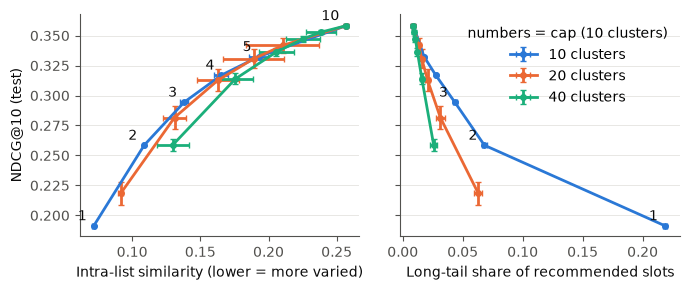

ndcg@10  intra-list similarity  long tail share  coverage  \
clusters cap                                                              
10       1      0.191                  0.072            0.219     0.417   
         2      0.259                  0.109            0.068     0.377   
         3      0.294                  0.138            0.043     0.377   
         4      0.317                  0.165            0.028     0.376   
         5      0.332                  0.193            0.018     0.369   
         10     0.358                  0.257            0.009     0.355   
20       1      0.218                  0.092            0.063     0.385   
         2      0.282                  0.131            0.031     0.377   
         3      0.313                  0.163            0.021     0.375   
         4      0.331                  0.189            0.016     0.371   
         5      0.342                  0.211            0.013     0.366   
         10     0.358                  0.257            0.009     0.355   
40       1      0.259                  0.130            0.026     0.376   
         2      0.314                  0.176            0.016     0.369   
         3      0.336                  0.206            0.012     0.366   
         4      0.347                  0.225            0.011     0.361   
         5      0.353                  0.238            0.010     0.357   
         10     0.358                  0.257            0.009     0.355   

              largest cluster share  
clusters cap                         
10       1                    0.100  
         2                    0.200  
         3                    0.299  
         4                    0.398  
         5                    0.495  
         10                   0.851  
20       1                    0.100  
         2                    0.199  
         3                    0.296  
         4                    0.387  
         5                    0.471  
         10                   0.728  
40       1                    0.100  
         2                    0.196  
         3                    0.285  
         4                    0.361  
         5                    0.420  
         10                   0.531

In [20]:
curve = diversity.groupby(["clusters", "cap"]).agg(["mean", "std"])
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0), sharey=True)
for k, part in curve.groupby(level="clusters"):
    for ax, x in zip(axes, ["intra-list similarity", "long tail share"]):
        ax.errorbar(part[(x, "mean")], part[("ndcg@10", "mean")], xerr=part[(x, "std")], yerr=part[("ndcg@10", "std")],
                    marker="o", ms=4, capsize=2, label=f"{k} clusters")
        for cap_value, row in part.iterrows():
            # caps labelled on one curve only, and not where the long-tail points crowd near zero
            if k == CLUSTER_KS[0] and (x == "intra-list similarity" or cap_value[1] in (1, 2, 3)):
                ax.annotate(str(cap_value[1]), (row[(x, "mean")], row[("ndcg@10", "mean")]),
                            xytext=(-5, 4), textcoords="offset points", ha="right", color=INK)
axes[0].set_xlabel("Intra-list similarity (lower = more varied)")
axes[1].set_xlabel("Long-tail share of recommended slots")
axes[0].set_ylabel("NDCG@10 (test)")
axes[1].legend(title=f"numbers = cap ({CLUSTER_KS[0]} clusters)", loc="upper right")
fig.tight_layout(w_pad=2.0)
fig.savefig(FIGURES / "diversity_tradeoff.pdf")
plt.show()

display(curve.xs("mean", axis=1, level=1)[["ndcg@10", "intra-list similarity", "long tail share", "coverage", "largest cluster share"]].round(3))

**Control: do the clusters matter, or would any cap do?** Any cap pushes the lists deeper into the ranking, which by itself lowers similarity and accuracy. On split 0 we repeat the capping with the cluster labels randomly shuffled between games (cluster sizes kept), three shuffles per cap, at the number of clusters from the curve that agrees best across random starts. If the clusters carry information, real clusters should give lower intra-list similarity than shuffled ones. Real clusters push the lists deeper into the ranking than shuffled ones at the same cap, so the fair comparison is at similar accuracy (NDCG), not only at the same cap.

In [21]:
control_k = int(sweep[sweep["k"].isin(CLUSTER_KS)].sort_values("seed agreement (ARI)")["k"].iloc[-1])
print(f"control at k = {control_k}")
popularity0 = evaluate.popularity_counts(train_full)
sim0 = baselines.item_similarity(baselines.pair_counts(train_full))
real_labels, _, _ = clusters.spherical_kmeans(final.item_factors, control_k, 0)  # as in the split-0 test run
rng = np.random.default_rng(0)
rows = []
for cap in [c for c in CAPS if c < ex.K]:
    for name, labels_used in [("real clusters", real_labels)] + [("shuffled", rng.permutation(real_labels)) for _ in range(3)]:
        recs = diversify.capped_top_k(evaluate.als_scorer(final), train_full, labels_used, cap, ex.K)
        metrics, _ = ex.list_metrics(recs, test, popularity0, sim0)
        rows.append({"cap": cap, "labels": name, **metrics})
control = pd.DataFrame(rows).groupby(["cap", "labels"])[["ndcg@10", "intra-list similarity", "long tail share"]].mean()
display(control.unstack("labels").round(3))

control at k = 10


ndcg@10          intra-list similarity          long tail share  \
labels real clusters shuffled         real clusters shuffled   real clusters   
cap                                                                            
1              0.191    0.329                 0.072    0.235           0.217   
2              0.259    0.356                 0.109    0.255           0.070   
3              0.295    0.359                 0.139    0.256           0.046   
4              0.318    0.359                 0.168    0.257           0.029   
5              0.333    0.359                 0.196    0.257           0.019   

                 
labels shuffled  
cap              
1         0.011  
2         0.009  
3         0.009  
4         0.009  
5         0.009

The report figure: the control as a trade-off curve. Both curves end at the uncapped split-0 lists (no cap), where the labels play no role.

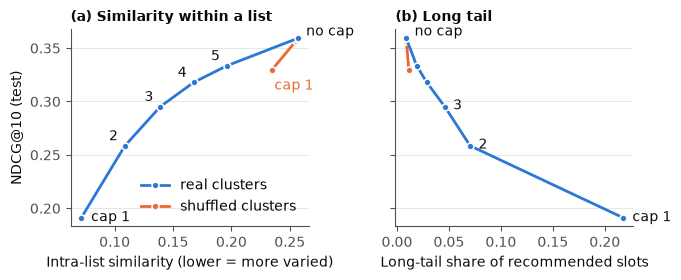

In [22]:
uncapped = diversity[(diversity["seed"] == 0) & (diversity["clusters"] == control_k) & (diversity["cap"] == ex.K)]
lines = {name: pd.concat([part.droplevel("labels").reset_index(), uncapped.assign(cap=ex.K)[part.columns.tolist() + ["cap"]]])
         for name, part in control.groupby(level="labels")}
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.9), sharey=True)
for ax, x, title in zip(axes, ["intra-list similarity", "long tail share"], ["(a) Similarity within a list", "(b) Long tail"]):
    for colour, name in [(SERIES[1], "shuffled"), (SERIES[0], "real clusters")]:
        line = lines[name]
        ax.plot(line[x], line["ndcg@10"], "-o", color=colour, ms=5, mec=SURFACE, mew=1.2,
                label="shuffled clusters" if name == "shuffled" else name)
    labelled = CAPS if x == "intra-list similarity" else [1, 2, 3, ex.K]  # the long-tail points crowd near zero
    for _, r in lines["real clusters"][lines["real clusters"]["cap"].isin(labelled)].iterrows():
        if r["cap"] == ex.K:
            ax.annotate("no cap", (r[x], r["ndcg@10"]), xytext=(6, 2), textcoords="offset points", color=INK)
        elif r["cap"] == 1:
            ax.annotate("cap 1", (r[x], r["ndcg@10"]), xytext=(7, 0), textcoords="offset points", color=INK, va="center")
        elif x == "intra-list similarity":
            ax.annotate(f"{r['cap']:.0f}", (r[x], r["ndcg@10"]), xytext=(-5, 4), textcoords="offset points", color=INK, ha="right")
        else:
            ax.annotate(f"{r['cap']:.0f}", (r[x], r["ndcg@10"]), xytext=(6, -2), textcoords="offset points", color=INK)
    ax.set_title(title, loc="left", color=INK, fontweight="bold")
first = lines["shuffled"].sort_values("cap").iloc[0]
axes[0].annotate("cap 1", (first["intra-list similarity"], first["ndcg@10"]), xytext=(2, -14), textcoords="offset points", color=SERIES[1])
axes[0].set_xlabel("Intra-list similarity (lower = more varied)")
axes[1].set_xlabel("Long-tail share of recommended slots")
axes[0].set_ylabel("NDCG@10 (test)")
handles, labels_ = axes[0].get_legend_handles_labels()
axes[0].legend(handles[::-1], labels_[::-1], loc="lower right")
fig.tight_layout(w_pad=2.0)
fig.savefig(FIGURES / "diversity_control.pdf")
plt.show()

## Summary of the results

Every number below is printed in this notebook or computed directly from a printed table. Test numbers are for split 0 unless they say "over splits". All methods use the same input: which games each user played.

**Data and tuning**
- 59,716 users × 3,718 games and 3.15M played pairs (1.42% of the matrix); every game has at least 20 training players (Section 1).
- Every best and every chosen setting lies inside the range tried, apart from the stated edges: pairs-only rules and the 512-factor compute cap. The edge extensions added 9 ALS settings, among them α = 100, which is worse than α = 30 (the α × λ table).
- Regularisation matters more than size. At 128 factors, raising λ from 1 to 300 lifts validation NDCG from 0.152 to 0.252; going from 64 to 512 factors adds 0.012, and from 256 to 512 only 0.001, each at its best λ (α = 10, the λ table).
- The best ALS setting is α = 30, 512 factors, λ = 375 (validation NDCG 0.2590), and the one-SE rule picks it (SE 0.0009). The best α = 10 setting is 0.0018 lower (0.2572).
- The least converged fits have little regularisation (λ = 1 or 30, NDCG 0.151–0.184) and still change their loss by 0.1–0.4% in the last sweep. All are far below the best, so no choice depends on them.
- For the chosen setting the loss is within 1% of its final value from sweep 6 for every start, and the three starts are within 0.0002 NDCG of each other at sweep 15. Mean NDCG peaks at sweep 8 (0.2595), 0.0005 above sweep 15 and about half a standard error, so the 15 sweeps used everywhere cost ALS almost nothing (Section 3).

**Test results**
- NDCG@10: ALS 0.359, rules 0.321–0.322, item-kNN 0.302, popularity 0.223. The order is the same on all five splits, and the standard deviation over splits is at most 0.0011 (Section 4).
- ALS beats the competitor that was best on validation (rules, pairs) by +0.038 NDCG, interval [0.036, 0.040] (Bonferroni, three comparisons). The rules beat popularity by +0.099, [0.097, 0.100].
- Triples add +0.0007 to the rules, [0.0000, 0.0014]: tiny, and the corrected interval reaches zero.
- Variety differs a lot between methods. Item-kNN recommends 51% of the games, ALS 36%, rules 6–7% and popularity 1%. 20.7% of the test-set plays (user–game pairs) are of long-tail games, but no method gives them more than 3.7% of its slots (item-kNN); ALS gives them 0.9%.
- Validation and test NDCG cannot be compared with each other: the test refit trains on 25% more games per user, and the test sets are larger (628,945 against 503,425 pairs). Compare methods within one set only. The lead of ALS over the rules (pairs) also grows, from 0.020 on validation to 0.038 on test. Part of this is scale: the methods score higher on test (rules 0.2395 → 0.321, about 1.34×), and relative to the rules the lead goes from about 8% to 12%. The rest may be that ALS gains more from the extra training games than the support-scaled rules (not measured).
- Long tail per slot (Section 6): ALS's 591,830 head slots are hits 23.0% of the time, its 5,330 long-tail slots 34.2%. Per game, a head game is in the test set of 671 users on average, a long-tail game in that of 44. So ALS recommends long-tail games rarely, but when it does they are hits more often than its head games.
- Running time (Section 4): ALS takes about 5 minutes to build (20.5 s per sweep, 15 sweeps), the rules with triples 23 s, the pair rules and item-kNN about 1 s. Making top-10 lists for all users takes 1–2 s for every method.

**Why the methods differ (our reading)**
- A rule's confidence P(game | premise) is high when the game is popular anyway, so rules mostly recommend the most-played games: 6–7% coverage and almost no long tail.
- Triples probably add little because the most frequent triples are combinations of the same few most-played games (the triple table in `frequent_itemsets.ipynb`, mined on all baskets at support 100), which the pair rules already cover (not measured).
- ALS combines all co-play at once in a low-dimensional model, while each rule looks at one small premise; with the same input, this is where its lead must come from.

**Implementation check:** in a fit at the chosen α and λ with 128 factors, our ALS and `implicit` differ by at most 1.2e-13 in score (first 5,000 users) and give identical top-10 lists for all 59,716 users (Section 5).

**Clusters and diversification**
- A vector's length follows the game's number of players (Spearman 0.99), so we cluster directions (Section 6).
- The Davies–Bouldin index falls overall from 3.350 at k = 5 to 2.740 at k = 80 and does not pick a k. Seed agreement is not monotone in k: it is above 0.9 at k = 5, 6, 7 and 10, but 0.81 at k = 8 and 0.75 at k = 9, so the threshold picks k = 10.
- At k = 10 the AMI with each game's top content tag is 0.192 (0.001 when shuffled). Six clusters are recognisable by their tags: strategy, difficult pixel platformers, MMO/survival/open world, shooters, JRPG/anime, and driving/racing/sports; three casual/2D clusters (two with Puzzle, one with Platformer) are hard to tell apart. The tenth cluster holds the most-played games (median 1,990 players, against 67–240 for the rest), mixes third-person, FPS and sandbox games, and gets 85% of all ALS top-10 slots, so the clusters partly follow popularity.
- Capping games per cluster trades accuracy for variety (Section 7, means over splits). With 10 clusters and a cap of 3, NDCG goes from 0.358 to 0.294, co-play similarity within a list from 0.257 to 0.138 and the long-tail share from 0.009 to 0.043. A cap of 1 brings NDCG to 0.191 and the long-tail share to 0.219.
- The shuffled-label control (split 0, 10 clusters) shows that the gain in variety comes from the clusters rather than from capping as such. With shuffled labels a cap of 2 or more changes almost nothing (NDCG 0.356–0.359, similarity 0.255–0.257). At similar accuracy, real clusters with a cap of 5 (NDCG 0.333) give lower similarity and more long tail than shuffled labels with a cap of 1 (NDCG 0.329): 0.196 against 0.235, and 0.019 against 0.011. Variety here means less co-play overlap, the same signal the clusters are learned from; the clusters only partly match genres (AMI 0.192).

## References

- Dhillon, I. S. & Modha, D. S. (2001). Concept decompositions for large sparse text data using clustering. *Machine Learning*, 42, 143–175.
- Efron, B. & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
- Ferrari Dacrema, M., Cremonesi, P. & Jannach, D. (2019). Are we really making much progress? A worrying analysis of recent neural recommendation approaches. *RecSys 2019*.
- Hu, Y., Koren, Y. & Volinsky, C. (2008). Collaborative filtering for implicit feedback datasets. *ICDM 2008*.
- Kang, W.-C. & McAuley, J. (2018). Self-attentive sequential recommendation. *ICDM 2018*.
- Leskovec, J., Rajaraman, A. & Ullman, J. D. (2020). *Mining of Massive Datasets*, 3rd ed. Cambridge University Press.
- Pathak, A., Gupta, K. & McAuley, J. (2017). Generating and personalizing bundle recommendations on Steam. *SIGIR 2017*.
- Vinh, N. X., Epps, J. & Bailey, J. (2010). Information theoretic measures for clusterings comparison: Variants, properties, normalization and correction for chance. *Journal of Machine Learning Research*, 11, 2837–2854.
- Wan, M. & McAuley, J. (2018). Item recommendation on monotonic behavior chains. *RecSys 2018*.